# YIN pitch detection on a clarinet

Roland FONTANES

YIN is the pitch detector used by the ClarinHelp tuner. The idea : a periodic sound
looks like itself when you shift it by one period. So we try every shift `tau` and
keep the first one where the shifted signal is almost the same.

The recordings are in `data/raw/` (not on GitHub).

## Loading a recording

##### 1. Load the clean take of Au clair de la lune and print its duration.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf

signal, sr = sf.read("../../data/raw/au_clair_clean_01.wav")
print(len(signal) / sr, "seconds at", sr, "Hz")

43.301458333333336 seconds at 48000 Hz


##### 2. Plot the waveform of the first notes.

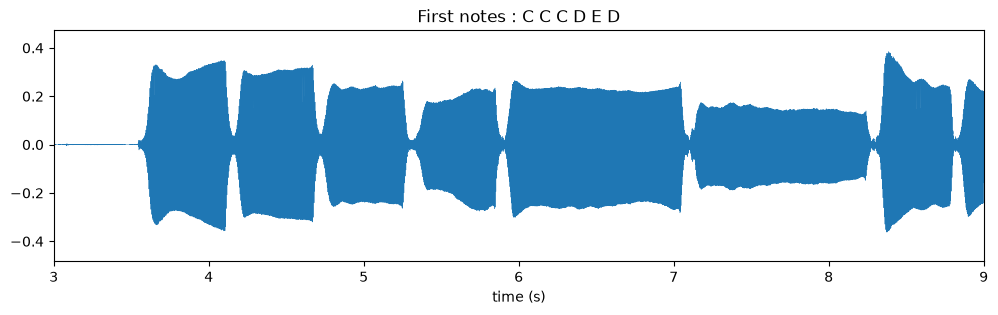

In [2]:
t = np.arange(len(signal)) / sr

plt.figure(figsize=(12, 3))
plt.plot(t, signal, linewidth=0.3)
plt.xlim(3, 9)
plt.xlabel("time (s)")
plt.title("First notes : C C C D E D")
plt.show()

Each block is a note. The small gaps between the 3 first blocks are the tongue
strokes between the repeated C.

##### 3. Take a frame of 2048 samples in the middle of the first note and plot it.

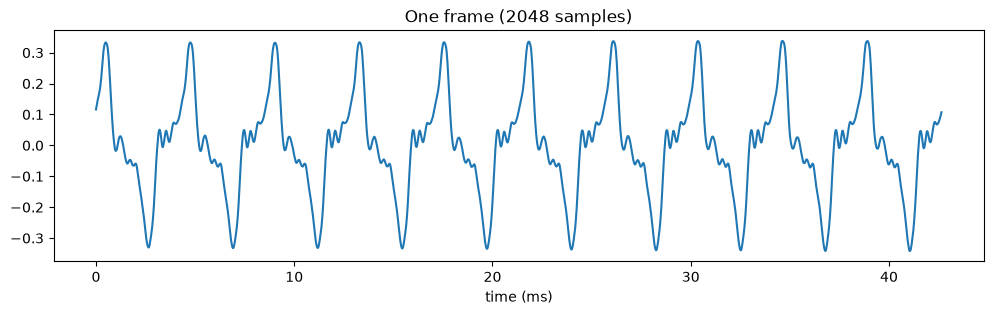

In [3]:
start = int(4.0 * sr)
frame = signal[start : start + 2048]

plt.figure(figsize=(12, 3))
plt.plot(np.arange(2048) / sr * 1000, frame)
plt.xlabel("time (ms)")
plt.title("One frame (2048 samples)")
plt.show()

The same shape repeats about 10 times in 43 ms, this is the period of the note.
The bumps inside each period are the harmonics, it's what makes it sound like a
clarinet and not a flute.

## YIN step by step

##### 4. Compute the difference function d(tau) = sum (x[j] - x[j + tau])² for every lag tau.

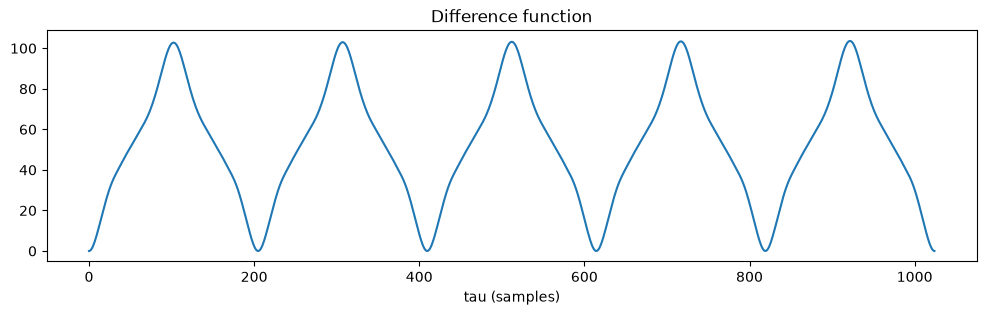

In [4]:
tau_max = 1024
w = 2048 - tau_max

d = np.zeros(tau_max + 1)
for tau in range(tau_max + 1):
    d[tau] = np.sum((frame[:w] - frame[tau : tau + w]) ** 2)

plt.figure(figsize=(12, 3))
plt.plot(d)
plt.xlabel("tau (samples)")
plt.title("Difference function")
plt.show()

It goes down close to 0 around every 205 samples : when we shift by 1, 2, 3...
periods the signal is the same again.

##### 5. Normalize it (cumulative mean normalized difference) and add the threshold 0.15.

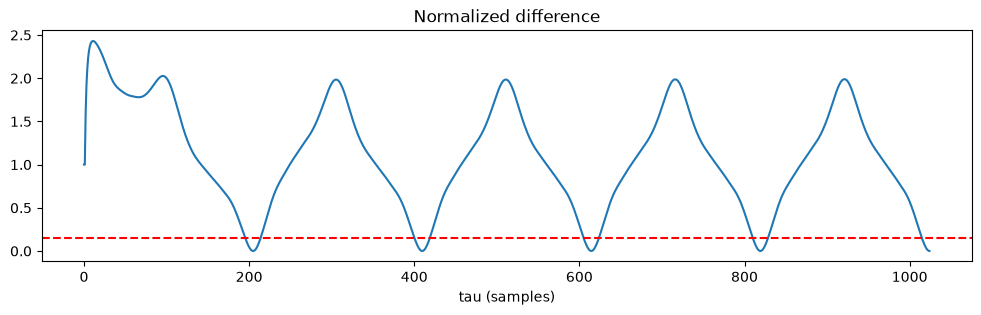

In [5]:
cmnd = np.ones(tau_max + 1)
cmnd[1:] = d[1:] * np.arange(1, tau_max + 1) / np.cumsum(d[1:])

plt.figure(figsize=(12, 3))
plt.plot(cmnd)
plt.axhline(0.15, color="red", linestyle="--")
plt.xlabel("tau (samples)")
plt.title("Normalized difference")
plt.show()

Now the curve starts at 1 and does not depend on the volume anymore, so the same
threshold works if I play loud or soft.

##### 6. Find the first dip under the threshold, then refine it with a parabola.

In [6]:
from clarinhelp.yin import parabolic_minimum

tau_min = sr // 2200  # highest note we look for: 2200 Hz
tau = tau_min
while cmnd[tau] >= 0.15:
    tau += 1
while cmnd[tau + 1] < cmnd[tau]:
    tau += 1

period = parabolic_minimum(cmnd, tau)
freq = sr / period
print("period:", period, "samples")
print("frequency:", freq, "Hz")

period: 204.82312731682634 samples
frequency: 234.3485358748195 Hz


##### 7. Convert it to a note (written pitch for a B♭ clarinet).

In [7]:
from clarinhelp.pitch import concert_to_written, midi_to_name, nearest_note

midi, cents = nearest_note(freq)
print("concert:", midi_to_name(midi))
print("written:", midi_to_name(concert_to_written(midi)))
print("cents:", cents)

concert: A#3
written: C4
cents: 9.382709187880067


234 Hz is a concert A#3, so a written C4 on the clarinet, which is the right note.
I am 9 cents sharp on this one.

##### 8. Compare with the yin() function of the project.

In [8]:
from clarinhelp.yin import yin

yin(frame, sr)

(np.float64(234.3518801655529), np.float64(0.9998792671135456))

Same note, only 0.003 Hz of difference : the project stops at 120 Hz (400 lags instead of 1024), so its window is a bit longer. The confidence is almost 1.

##### 9. Plot the multiples of the period on the normalized difference.

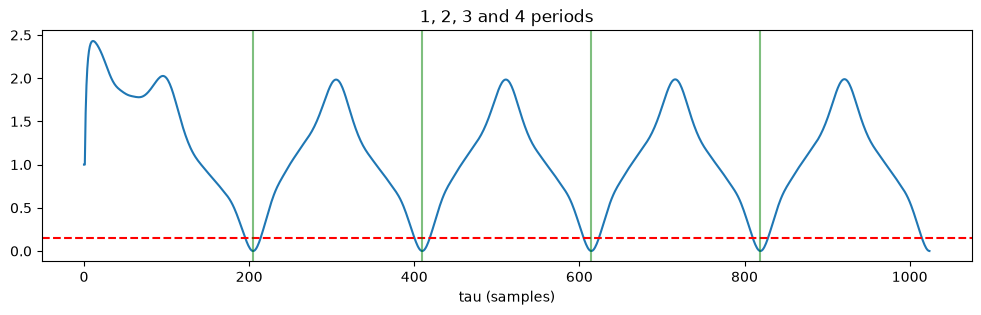

In [9]:
plt.figure(figsize=(12, 3))
plt.plot(cmnd)
plt.axhline(0.15, color="red", linestyle="--")
for k in [1, 2, 3, 4]:
    plt.axvline(k * period, color="green", alpha=0.5)
plt.xlabel("tau (samples)")
plt.title("1, 2, 3 and 4 periods")
plt.show()

All the dips go down to 0. If we took the lowest one instead of the first one, we
could pick 2 or 3 periods and get a note one octave (or more) too low. That's why
YIN takes the first dip.

##### 10. Try YIN on silence and on white noise.

In [10]:
silence = signal[sr : sr + 2048]  # 1 s, before the first note
noise = np.random.uniform(-1, 1, 2048)

print("silence:", yin(silence, sr))
print("noise:", yin(noise, sr))

silence: None
noise: None


Nothing repeats so the curve never goes under the threshold : no note.

## On the whole recording

##### 11. Run YIN on every frame (one every 1024 samples, like the live tuner).

In [11]:
from clarinhelp.pitch import hz_to_midi
from clarinhelp.yin import track

times, freqs, rms = track(signal, sr)
written = concert_to_written(hz_to_midi(freqs))
print(len(times), "frames")

2028 frames


##### 12. Plot the notes found by YIN with the annotations in grey.

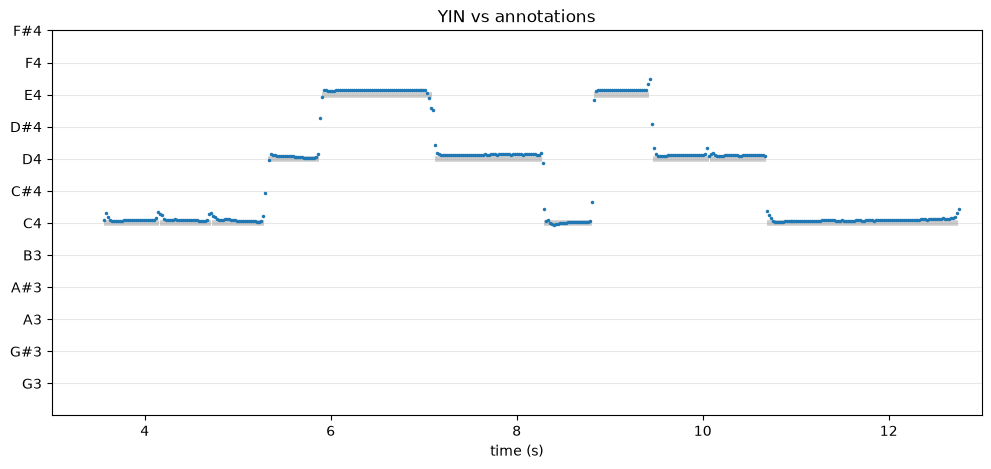

In [12]:
from clarinhelp.labels import read_labels
from clarinhelp.pitch import name_to_midi

labels = read_labels("../../data/annotations/au_clair_clean_01.txt")

plt.figure(figsize=(12, 5))
for start, end, note in labels:
    plt.hlines(name_to_midi(note), start, end, color="grey", linewidth=4, alpha=0.4)
plt.plot(times, written, ".", markersize=3)
notes = range(55, 67)
plt.yticks(notes, [midi_to_name(n) for n in notes])
plt.ylim(54, 66)
plt.xlim(3, 13)
plt.grid(axis="y", alpha=0.3)
plt.xlabel("time (s)")
plt.title("YIN vs annotations")
plt.show()

YIN follows the annotations well. The blue points are always a bit above the grey
lines, I play a little sharp on this recording.

##### 13. Plot the level of the same part.

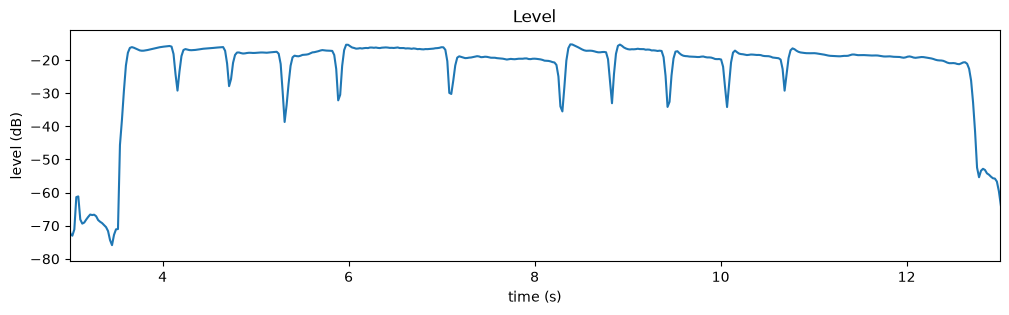

In [13]:
level = 20 * np.log10(rms)

plt.figure(figsize=(12, 3))
plt.plot(times, level)
plt.xlim(3, 13)
plt.xlabel("time (s)")
plt.ylabel("level (dB)")
plt.title("Level")
plt.show()

The 3 first C have the same pitch, so YIN alone sees one long note. What separates
them is the small dip in level at each tongue stroke.